# Setup

In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

install.packages("pROC")
library(pROC)

install.packages("pheatmap")
library(pheatmap)


## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

# Get the bucket name
my_bucket <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/"

[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite

Warning message:
“package ‘viridisLite’ was built under R version 4.4.3”
Warning message:
“package ‘scales’ was built under R version 4.4.3”

Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal


Warning message:
“package ‘lubridate’ was built under R version 4.4.3”
Warning message:
“Your system is mis-configured: ‘/var/db/timezone/localtime’ is not a symlink”
Warning message:
“‘/var/db/timezone/localtime’ is not identical to any known timezone file”
Warning message:
“Failed to locate timezone database”

Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


Warning message:
“package ‘tidyverse’ was built under R version 4.4.3”
Warning message:
“package ‘tibble’ was built under R version 4.4.3”
Warning message:
“package ‘tidyr’ was built under R version 4.4.3”
Warning message:
“package ‘readr’ was built under R version 4.4.3”
Wa

## Load and merge data

In [2]:
#Load demographic data
name_of_file_in_bucket <- 'Demographic_and_ancestry_covariates.csv'
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)
demo  <- read_csv(name_of_file_in_bucket) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

#Load SES data
name_of_file_in_bucket <- 'SES_data.csv'
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)
sdoh_data  <- read_csv(name_of_file_in_bucket)

#MERGE
demo_sdoh<-merge(demo, sdoh_data, on="person_id", how="inner")

#Load PRS data
name_of_file_in_bucket <- 'adjusted_PRS_scores.csv'
system(paste0("gsutil cp ", my_bucket, "/data/", name_of_file_in_bucket, " ."), intern=T)
PRS  <- read_csv(name_of_file_in_bucket) 

#MERGE
all_data_0<-merge(demo_sdoh, PRS, on="person_id", how="inner")

#Load Case control info 
name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://rw-migration-aou-rw-55feedb6/notebooks/Case_Control_df.csv ."), intern=T)
case_control  <- read_csv(name_of_file_in_bucket)


character(0)

Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, lower_poverty...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 135557 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): person_id, Asthma_adjusted_score, Afib_adjusted_score, BreastC_adju...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
#MERGE
merged_data<-merge(all_data_0, case_control, on="person_id", how="left")
colnames(merged_data)

merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

[1] "person_id"                         "date_of_birth"                    
 [3] "AIAN"                              "Asian"                            
 [5] "Black"                             "Mid"                              
 [7] "Multiple"                          "PI"                               
 [9] "White"                             "His"                              
[11] "race_unknown"                      "SexGender"                        
[13] "age_today"                         "ancestry_pred"                    
[15] "PC_1"                              "PC_2"                             
[17] "PC_3"                              "PC_4"                             
[19] "PC_5"                              "PC_6"                             
[21] "PC_7"                              "PC_8"                             
[23] "PC_9"                              "PC_10"                            
[25] "PC_11"                             "PC_12"                            
[27] "PC_13"                             "PC_14"                            
[29] "PC_15"                             "PC_16"                            
[31] "number_living"                     "where_born"                       
[33] "military"                          "healthcare"                       
[35] "disabled"                          "sexual_orientation"               
[37] "LGBTQIA"                           "basics_survey_datetime"           
[39] "income_grouped"                    "min_date"                         
[41] "max_date"                          "ehr_length"                       
[43] "relative_health"                   "record_depth"                     
[45] "visit_frequency"                   "age"                              
[47] "record_depth_winsorized"           "visit_frequency_winsorized"       
[49] "age2"                              "income"                           
[51] "education"                         "per_poverty_threshold"            
[53] "lower_poverty"                     "american_community_survey_year"   
[55] "fraction_assisted_income"          "fraction_no_high_school_education"
[57] "lower_median_income"               "fraction_no_health_insurance"     
[59] "fraction_poverty"                  "fraction_vacant_housing"          
[61] "deprivation_index"                 "Asthma_adjusted_score"            
[63] "Afib_adjusted_score"               "BreastC_adjusted_score"           
[65] "CKD_adjusted_score"                "CHD_adjusted_score"               
[67] "ProstateC_adjusted_score"          "t1d_adjusted_score"               
[69] "t2d_adjusted_score"                "Asthma"                           
[71] "Afib"                              "BreastC"                          
[73] "CKD"                               "CHD"                              
[75] "HyperC"                            "ProstateC"                        
[77] "t2d"                               "t1d"

## Set up lists

In [4]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")

sdoh_var <-c('lower_poverty', 'education',
         'fraction_assisted_income', 'fraction_no_high_school_education', 'lower_median_income', 
         'fraction_no_health_insurance', 'fraction_poverty', 'fraction_vacant_housing', 'deprivation_index'
)

social_name_mapping <- c(
  "lower_poverty" = " Individual \nPoverty",
  "education" = "Individual\nEducation",
  "fraction_assisted_income" = "Assisted\nIncome (%)",
  "fraction_no_high_school_education" = "High School\nEducation (%)",
  "lower_median_income" = " Median Income ",
  "fraction_no_health_insurance" = "Health\nInsurance (%)",
  "fraction_poverty" = "Poverty (%)", 
  "fraction_vacant_housing" = "Vacant\nHousing (%)",
  "deprivation_index" = "Deprivation\nIndex"
)

social_name_mapping_distributions <- c(
"lower_poverty" = "Lower Individual Poverty",
  "education" = "Lower Individual Education", 
  "fraction_assisted_income" = "Assisted Income (%)",
  "fraction_no_high_school_education" = "No High School Education (%)",
  "lower_median_income" = "Lower Area Median Income",
  "fraction_no_health_insurance" = "No Health Insurance (%)",
  "fraction_poverty" = "Poverty (%)",
  "fraction_vacant_housing" = "Vacant Housing (%)",
  "deprivation_index" = "Area Deprivation Index"
)

disease_name_mapping <- c(
  "Asthma" = "Asthma",
    "Afib" = "Afib",
    "BreastC" = "Breast\nCancer",
    "CKD" = "CKD", 
    "CHD" = "CHD",
    "ProstateC" = "Prostate\nCancer", 
  "t2d" = "T2D",
  "t1d" = "T1D"
)

disease_order <- c("Breast\nCancer", "Prostate\nCancer", "Afib", 
                   "T2D", "CKD", "CHD",
                  "Asthma", "T1D")

sdoh_order <- c('Individual\nEducation', ' Individual \nPoverty','Assisted\nIncome (%)',
           'High School\nEducation (%)', ' Median Income ',
           'Health\nInsurance (%)', 'Poverty (%)', 'Vacant\nHousing (%)', 'Deprivation\nIndex')


## -----------------------------
## Bonferroni correction
## -----------------------------
n_disease <- length(diseases)
n_sdoh    <- length(sdoh_var)
alpha_bonf <- 0.05 / (n_disease * n_sdoh)

alpha_bonf 

[1] 0.0006944444

## Plot distributions

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


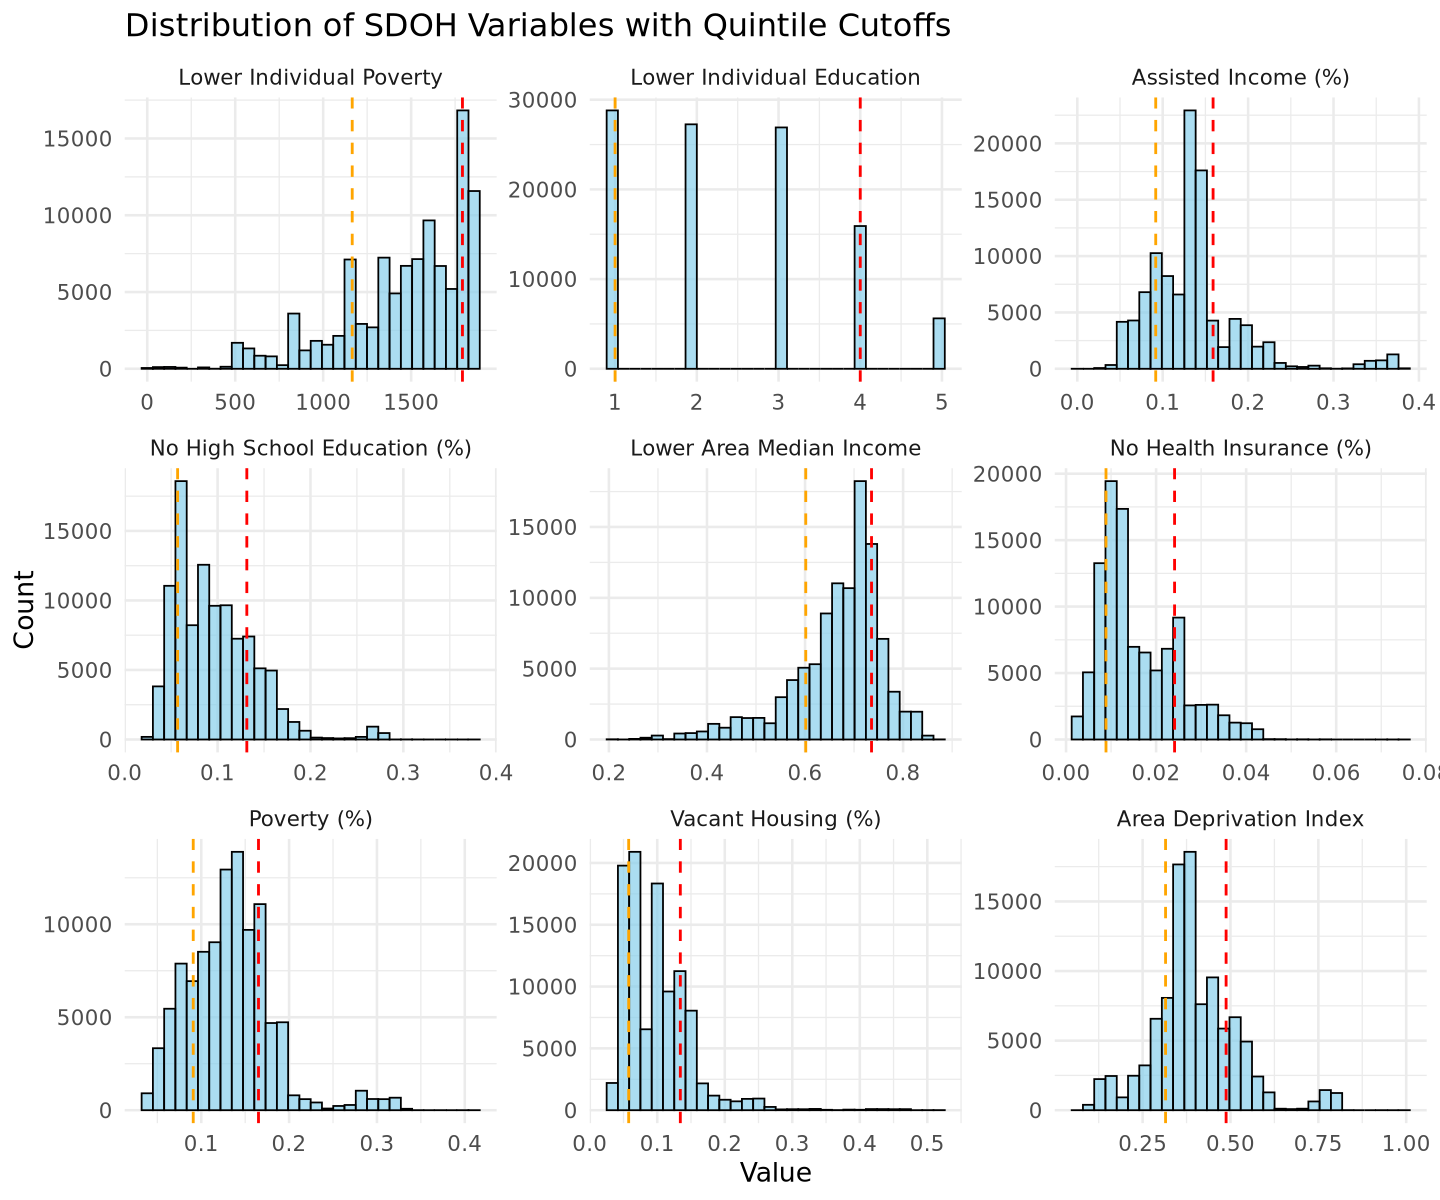

In [5]:
options(
    repr.plot.width  = 12,
    repr.plot.height = 10
  )

# --- Reshape to long format ---
long_data <- merged_data %>%
  select(all_of(sdoh_var)) %>%
  pivot_longer(cols = everything(), names_to = "domain", values_to = "value")

#Clean up
long_data$domain <- social_name_mapping_distributions[long_data$domain]

#Order
sdoh_distribution_order <- c( "Lower Individual Poverty", "Lower Individual Education",  "Assisted Income (%)",
  "No High School Education (%)", "Lower Area Median Income", "No Health Insurance (%)",
  "Poverty (%)", "Vacant Housing (%)", "Area Deprivation Index"
)

long_data <- long_data %>%
    mutate(
      domain       = factor(domain, levels = sdoh_distribution_order ))

# --- Calculate quintiles per domain ---
quantiles <- long_data %>%
  group_by(domain) %>%
  summarize(
    q1 = quantile(value, 0.2, na.rm = TRUE),
    q5 = quantile(value, 0.8, na.rm = TRUE)
  )

# --- Merge quantiles back for plotting ---
plot_data <- long_data %>%
  left_join(quantiles, by = "domain")

# --- Faceted histogram plot ---
ggplot(plot_data, aes(x = value)) +
  geom_histogram(bins = 30, fill = "skyblue", color = "black", alpha = 0.7) +
  geom_vline(aes(xintercept = q1), color = "orange", linetype = "dashed", size = 0.8) +
  geom_vline(aes(xintercept = q5), color = "red", linetype = "dashed", size = 0.8) +
  facet_wrap(~ domain, scales = "free") +
  labs(x = "Value", y = "Count", title = "Distribution of SDOH Variables with Quintile Cutoffs") +
  theme_minimal(base_size = 16)



In [6]:
long_data |>
  group_by(domain) |>
  summarise(
    across(
      where(is.numeric),
      list(
        mean = ~ round(mean(.x, na.rm = TRUE), 3),
        median = ~ round(median(.x, na.rm =TRUE), 3),
        sd   = ~ round(sd(.x, na.rm = TRUE), 3),
        min  = ~ round(min(.x, na.rm = TRUE), 3),
        max  = ~ round(max(.x, na.rm = TRUE), 3), 
        q1   = ~ round(quantile(.x, 0.20, na.rm = TRUE), 3),
        q5   = ~ round(quantile(.x, 0.80, na.rm = TRUE), 3)
      ),
      .names = "{.col}_{.fn}"
    ),
    n = n(),
    .groups = "drop"
  )

domain,value_mean,value_median,value_sd,value_min,value_max,value_q1,value_q5,n
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
Lower Individual Poverty,1463.058,1535.703,351.571,0.000,1858.094,1165.111,1791.751,104508
Lower Individual Education,2.448,2.000,1.194,1.000,5.000,1.000,4.000,104508
Assisted Income (%),0.136,0.134,0.057,0.000,0.383,0.092,0.159,104508
No High School Education (%),0.097,0.088,0.044,0.018,0.370,0.057,0.131,104508
Lower Area Median Income,0.668,0.688,0.094,0.217,0.884,0.601,0.736,104508
No Health Insurance (%),0.016,0.013,0.009,0.003,0.076,0.009,0.024,104508
Poverty (%),0.132,0.130,0.050,0.039,0.411,0.091,0.165,104508
Vacant Housing (%),0.100,0.097,0.051,0.031,0.515,0.058,0.134,104508
Area Deprivation Index,0.398,0.386,0.123,0.070,1.000,0.315,0.488,104508


### Check case distribution

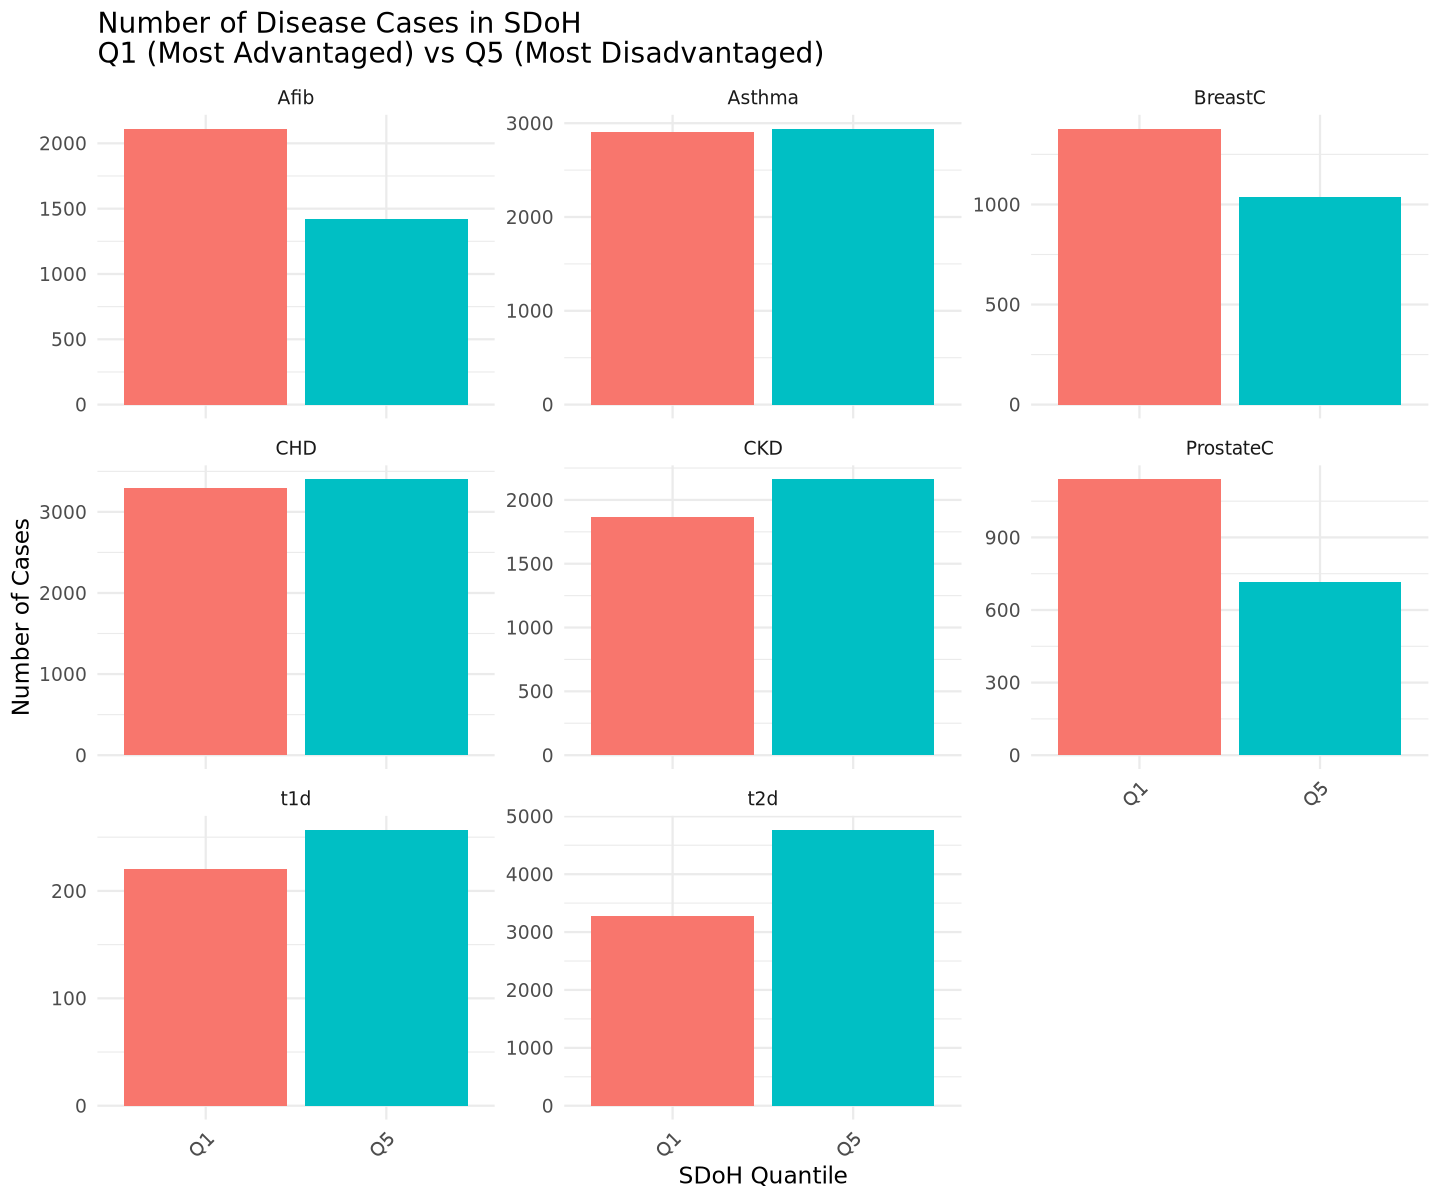

In [7]:
count_cases_by_quantile <- function(disease, sdoh_var, data, n_quantiles = 5) {
  
  # filter for disease column present
  stopifnot(disease %in% names(data))
  stopifnot(sdoh_var %in% names(data))
  
  data %>%
    filter(!is.na(.data[[sdoh_var]])) %>%
    
    # create quantiles
    mutate(quantile_group = ntile(.data[[sdoh_var]], n_quantiles)) %>%
    
    # summarize cases and noncases
    group_by(quantile_group) %>%
    summarise(
      Disease = disease,
      SDoH_Variable = sdoh_var,
      n_total = n(),
      n_cases = sum(.data[[disease]] == 1, na.rm = TRUE),
      n_controls = sum(.data[[disease]] == 0, na.rm = TRUE),
      case_rate = n_cases / n_total,
      .groups = "drop"
    ) %>%
    arrange(quantile_group)
}

# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

case_count_table <- combinations %>%
  rowwise() %>%
  mutate(
    case_counts = list(count_cases_by_quantile(disease, sdoh_var, merged_data))
  ) %>%
  unnest(case_counts)

q1_q5_counts <- case_count_table %>%
  filter(quantile_group %in% c(1, 5)) %>%
  mutate(
    quantile_label = ifelse(quantile_group == 1, "Q1", "Q5")
  )


ggplot(q1_q5_counts, aes(x = quantile_label, y = n_cases, fill = quantile_label)) +
  geom_col(position = "dodge") +
  facet_wrap(~ Disease, scales = "free_y") +
  labs(
    title = "Number of Disease Cases in SDoH\nQ1 (Most Advantaged) vs Q5 (Most Disadvantaged)",
    x = "SDoH Quantile",
    y = "Number of Cases",
    fill = "Quantile"
  ) +
  theme_minimal(base_size = 14) +
  theme(
    legend.position = "none",
    axis.text.x = element_text(angle = 45, hjust = 1)
  )


# Regressions

## Make functions

In [8]:
generate_formulas <- function(disease) {
  # Base covariates
  covariates <- c("age", "age2", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease %in% c("CKD", "t1d")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease %in% c("BreastC", "ProstateC")) {
    sex_terms <- character(0)
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")

  as.formula(paste(disease, "~", paste(c(base, score), collapse = " + ")))
}

fit_by_quantiles <- function(formula, disease, sdoh_var, data, n_quantiles = 5) {
  
  # Create quantile groups
  data <- data %>%
    filter(!is.na(.data[[sdoh_var]])) %>%
    mutate(quantile_group = ntile(.data[[sdoh_var]], n_quantiles))
    
  # Disease specific filters
  if (disease %in% c("CKD", "t1d")) data <- data %>% filter(SexGenderSGM == 0)
  if (disease == "BreastC")         data <- data %>% filter(SexGenderCis_female == 1)
  if (disease == "ProstateC")       data <- data %>% filter(SexGenderCis_male == 1)

  # Fit models for each quantile group
  results <- data %>%
    group_by(quantile_group) %>%
    group_map(~ {

      # Fit the model
      model <- glm(formula, data = .x, family = binomial(link = "logit"))
      
      # Calculate predictions and AUC
      preds <- predict(model, type = "response")
      actuals <- model$y

      if (length(unique(actuals)) > 1) {
        roc_obj <- roc(actuals, preds, quiet = TRUE)
        auc <- as.numeric(roc_obj$auc)
        auc_ci <- ci.auc(roc_obj)
      } else {
        auc <- NA
        auc_ci <- c(NA, NA, NA)
      }
      
      # Extract model coefficients
      tidy(model) %>%
        mutate(
          Disease = disease,
          Quantile_Group = .y$quantile_group,  # Properly carried from the group key
          SDoH_Variable = sdoh_var,
          AUC = auc,
          AUC_CI_Lower = auc_ci[1],
          AUC_CI_Upper = auc_ci[3],
          OR = exp(estimate),
         OR_Lower = exp(estimate - 1.96 * std.error),
         OR_Upper = exp(estimate + 1.96 * std.error)
        )
    }) %>%
    bind_rows()

  return(results)
}

## Run

In [9]:
# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles(formula, disease, sdoh_var, merged_data))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)


#Clean up results
results<-results[results$Quantile_Group %in% c(1,5), ] #Only interested in top and bottom quantiles
results <- results[grep("adjusted_score", results$term), ] #Only interested in PRS term

#Map names for display
results$SDoH_Variable <- social_name_mapping[results$SDoH_Variable] 
results$Disease <- disease_name_mapping[results$Disease]

## -----------------------------
## Recode + order factors
## -----------------------------
results <- results %>%
    mutate(
      Disease       = factor(Disease, levels = disease_order),
      SDoH_Variable = factor(SDoH_Variable, levels = sdoh_order),
      Quantile      = paste0("Q", Quantile_Group)
    ) %>%
    select(
      Disease, SDoH_Variable, Quantile_Group, Quantile,
      term, estimate, std.error, statistic, p.value,
      OR, OR_Lower, OR_Upper,
      AUC, AUC_CI_Lower, AUC_CI_Upper
    )

Warning message:
“There were 17 warnings in `mutate()`.
The first warning was:
ℹ In argument: `quantile_results = list(fit_by_quantiles(formula, disease,
  sdoh_var, merged_data))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 16 remaining warnings.”


# Graph PRS Odds Ratios 

## Prepare data

In [10]:
prepare_sdoh_prs_forest_data <- function(
  results
) {

  ## -----------------------------
  ## Wide table for Q5 vs Q1 contrast
  ## -----------------------------
  wide <- results %>%
    select(
      Disease, SDoH_Variable, Quantile_Group, estimate,
      OR, std.error, OR_Upper, OR_Lower
    ) %>%
    tidyr::pivot_wider(
      names_from  = Quantile_Group,
      values_from = c(estimate, OR, std.error, OR_Upper, OR_Lower),
      names_sep   = "_"
    )

  ## -----------------------------
  ## z-test + significance flags
  ## -----------------------------
  ann_df <- wide %>%
  mutate(
    var_OR_5 = (OR_5 * std.error_5)^2,
    var_OR_1 = (OR_1 * std.error_1)^2,
    z  = (OR_5 - OR_1) / sqrt(var_OR_5 + var_OR_1),
    z_test_p_value = 2 * pnorm(-abs(z)),
    bonf_sig = z_test_p_value < alpha_bonf,
    fdr_sig      = p.adjust(z_test_p_value, method = "BH") < 0.05,
    sig = z_test_p_value < 0.05
  )

  ## -----------------------------
  ## Join back to long dataframe
  ## -----------------------------
  estimate_q15_out <- results %>%
    left_join(
      ann_df %>%
        select(Disease, SDoH_Variable, z, z_test_p_value, bonf_sig, fdr_sig, sig),
      by = c("Disease", "SDoH_Variable")
    )

  estimate_q15_out
}

estimate_q15_out <- prepare_sdoh_prs_forest_data(results)

#Save table
destination_filename <- 'OR_stratified_analyses.csv'
write_excel_csv(estimate_q15_out, destination_filename)
system(paste0("gsutil cp ./", destination_filename, " ", my_bucket, "/data/"), intern=T)
system(paste0("gsutil cp ", my_bucket, "/data/", destination_filename, " ."), intern=T)

character(0)

character(0)

## Plot

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_errorbarh()`).”
Warning message:
“Removed 72 rows containing missing values or values outside the scale range
(`geom_vline()`).”


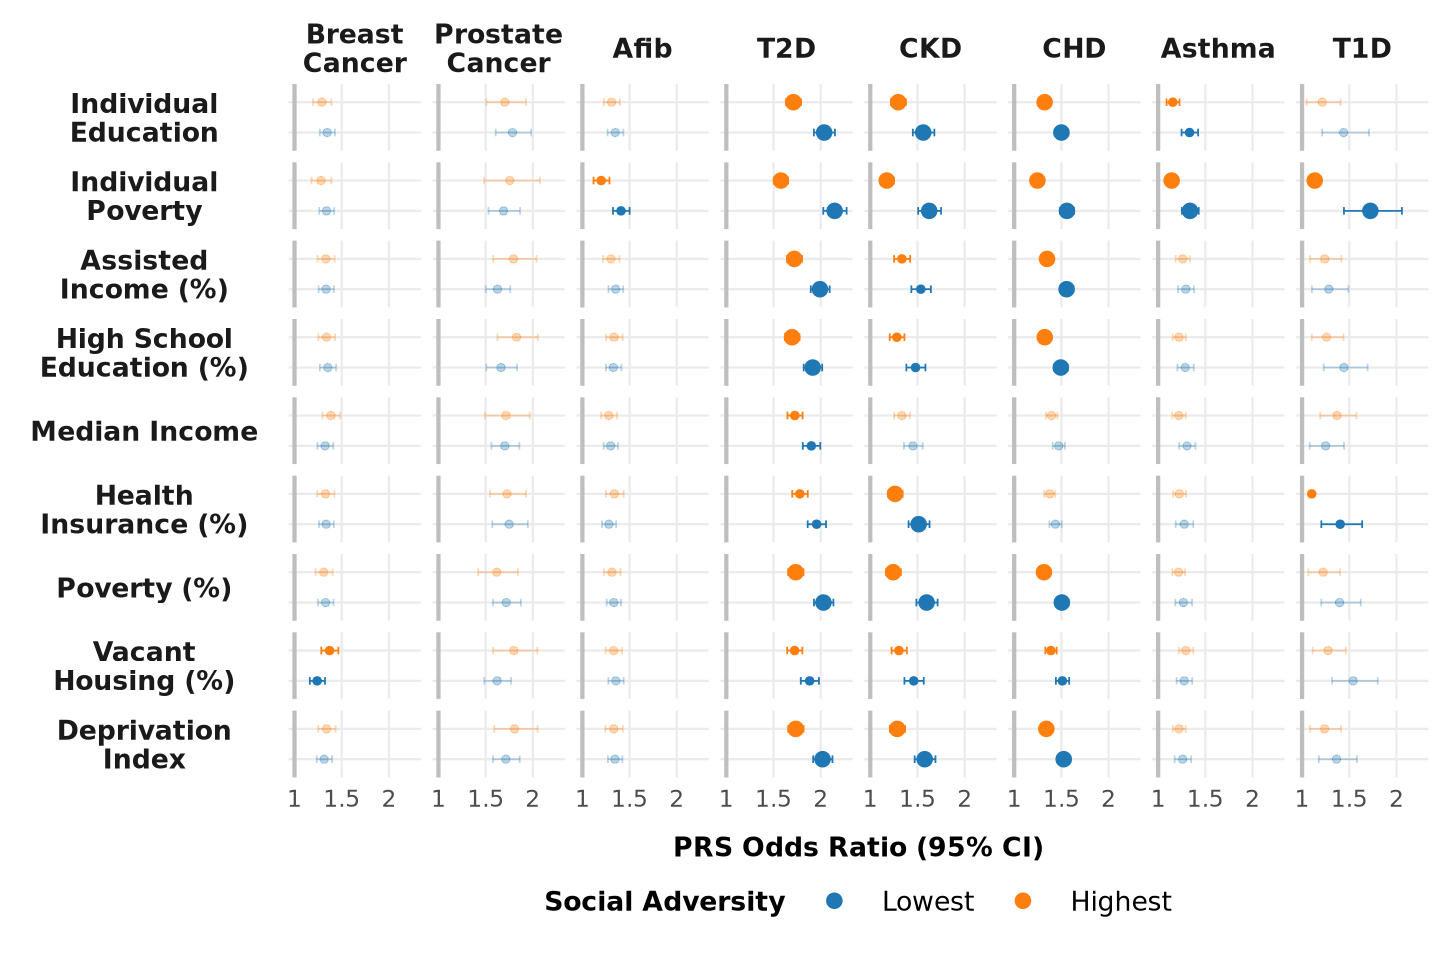

In [11]:
plot_sdoh_prs_forest <- function(
  df,
  width  = 12,
  height = 8,
  x_label = "PRS Odds Ratio (95% CI)"
) {

  p <- ggplot(
    df,
    aes(x = OR, y = Quantile, color = Quantile)
  ) +

    # Error bars (fade if not significant)
    geom_errorbarh(
      aes(
        xmin = OR_Lower,
        xmax = OR_Upper,
        alpha = sig
      ),
      height = 0.25,
      show.legend = FALSE
    ) +

    # Reference lines
    geom_vline(xintercept = 0, color = "grey", linewidth = 1.2) +
    geom_vline(xintercept = 1, color = "grey", linewidth = 1.2) +

    # Points
    geom_point(
      aes(
        alpha = sig,
        size  = bonf_sig
      )
    ) +

    scale_x_continuous(
      name   = x_label,
      breaks = c(1, 1.5, 2),
        labels = function(x) sub("\\.0$", "", as.character(x)),
      limits = c(
        1,
        max(1, max(df$OR_Upper, na.rm = TRUE))
      )
    ) +

    scale_color_manual(
      values = c(Q1 = "#1f77b4", Q5 = "#ff7f0e"),
      labels = c(
        Q1 = "Lowest",
        Q5 = "Highest"
      )
    ) +

    scale_size_manual(
      values = c(`FALSE` = 2, `TRUE` = 4),
      guide  = "none"
    ) +

    scale_alpha_manual(
      values = c(`FALSE` = 0.3, `TRUE` = 1),
      guide  = "none"
    ) +

    labs(
      y     = "Quantile",
      color = "Social Adversity"
    ) +

    facet_grid(
      rows   = vars(SDoH_Variable),
      cols   = vars(Disease),
      scales = "free_y",
      switch = "y"
    ) +

    theme_minimal(base_size = 14) +
    theme(
      axis.text.x        = element_text(size = 14, margin = margin(t = 4), angle = 0),
      panel.grid.minor   = element_blank(),
      axis.title.y       = element_blank(),
      axis.title.x       = element_text(size = 16, face = "bold", margin = margin(t = 15)),
      axis.text.y        = element_blank(),
      strip.text.y.left  = element_text(size = 16, angle = 0, face = "bold", vjust = 0.5),
      strip.placement    = "outside",
      strip.text.x       = element_text(size = 16, face = "bold"),
      legend.position    = "bottom",
      legend.box.spacing = unit(-5, "pt"),
      legend.text        = element_text(size = 16),
      legend.title       = element_text(size = 16, face = "bold"),
      legend.key.size    = unit(3, "lines")
    ) +

    guides(
      color = guide_legend(override.aes = list(size = 4))
    )

  options(
    repr.plot.width  = width,
    repr.plot.height = height
  )

  p
}

p_forest <- plot_sdoh_prs_forest(estimate_q15_out)
print(p_forest)

# Redo Controlling for PCs

In [12]:
generate_formulas <- function(disease) {
  # Base covariates
  covariates <- c("age", "record_depth", "visit_frequency", paste0("PC_", 1:16))
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease %in% c("CKD", "t1d")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease %in% c("BreastC", "ProstateC")) {
    sex_terms <- character(0)
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")

  as.formula(paste(disease, "~", paste(c(base, score), collapse = " + ")))
}

# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles(formula, disease, sdoh_var, merged_data))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)

#Clean up results
results<-results[results$Quantile_Group %in% c(1,5), ] #Only interested in top and bottom quantiles
results <- results[grep("adjusted_score", results$term), ] #Only interested in PRS term

#Map names for display
results$SDoH_Variable <- social_name_mapping[results$SDoH_Variable] 
results$Disease <- disease_name_mapping[results$Disease]

## -----------------------------
## Recode + order factors
## -----------------------------
results <- results %>%
    mutate(
      Disease       = factor(Disease, levels = disease_order),
      SDoH_Variable = factor(SDoH_Variable, levels = sdoh_order),
      Quantile      = paste0("Q", Quantile_Group)
    ) %>%
    select(
      Disease, SDoH_Variable, Quantile_Group, Quantile,
      term, estimate, std.error, statistic, p.value,
      OR, OR_Lower, OR_Upper,
      AUC, AUC_CI_Lower, AUC_CI_Upper
    )

Warning message:
“There were 17 warnings in `mutate()`.
The first warning was:
ℹ In argument: `quantile_results = list(fit_by_quantiles(formula, disease,
  sdoh_var, merged_data))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 16 remaining warnings.”


character(0)

character(0)

Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_errorbarh()`).”
Warning message:
“Removed 72 rows containing missing values or values outside the scale range
(`geom_vline()`).”


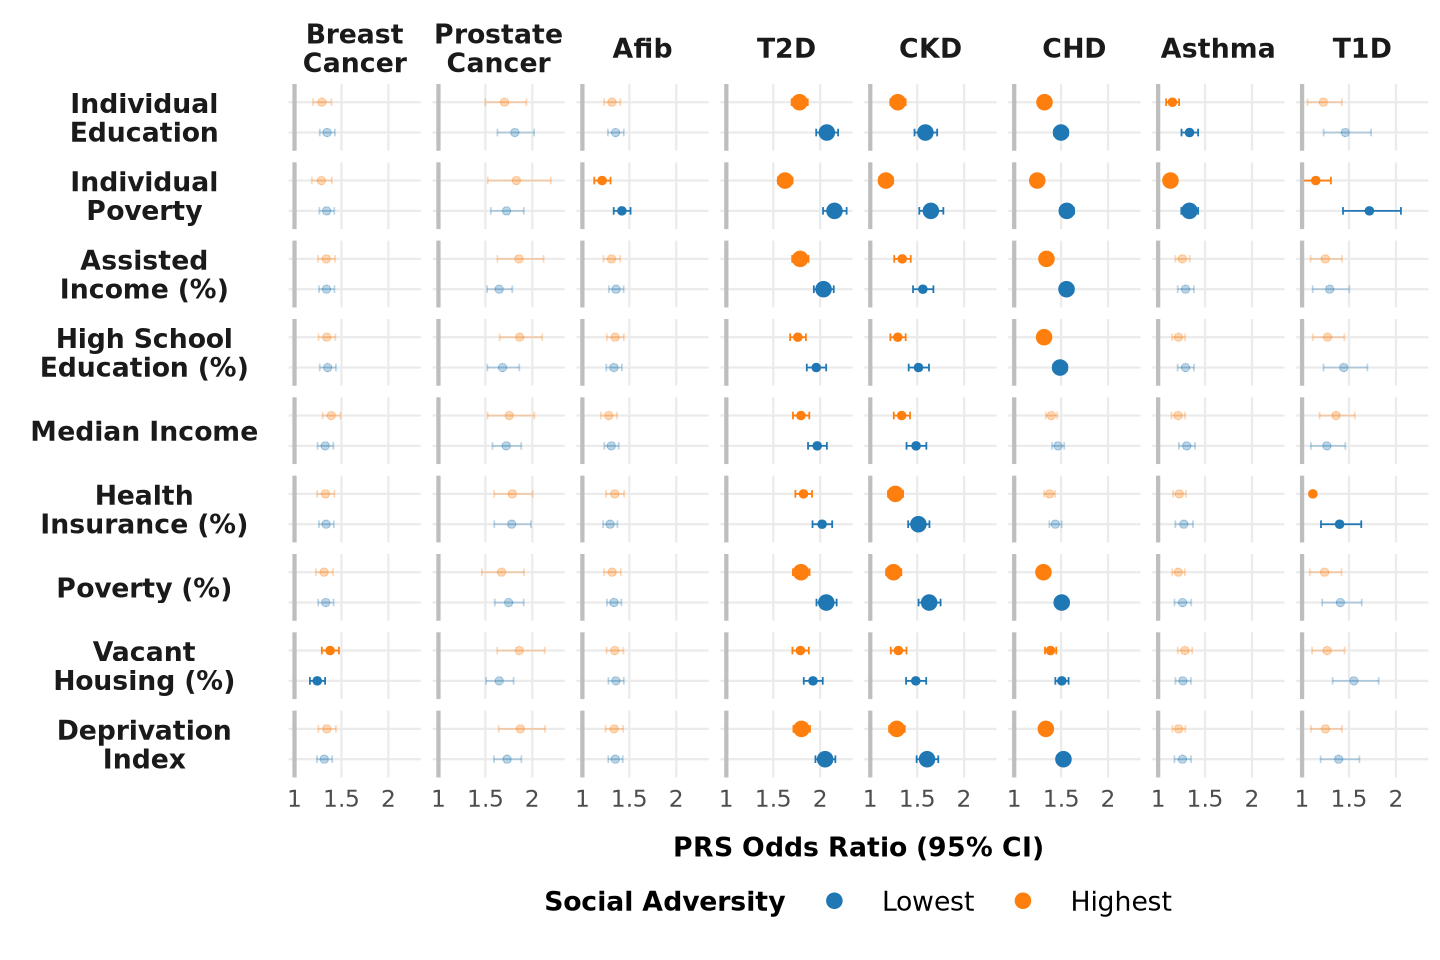

In [13]:
estimate_q15_out <- prepare_sdoh_prs_forest_data(results)

#Save table
destination_filename <- 'OR_stratified_analyses_controlling_PCs.csv'
write_excel_csv(estimate_q15_out, destination_filename)
system(paste0("gsutil cp ./", destination_filename, " ", my_bucket, "/data/"), intern=T)
system(paste0("gsutil cp ", my_bucket, "/data/", destination_filename, " ."), intern=T)

p_forest <- plot_sdoh_prs_forest(estimate_q15_out)
print(p_forest)

# Sensitivity analysis just PRS no covariates

character(0)

character(0)

Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_errorbarh()`).”
Warning message:
“Removed 72 rows containing missing values or values outside the scale range
(`geom_vline()`).”


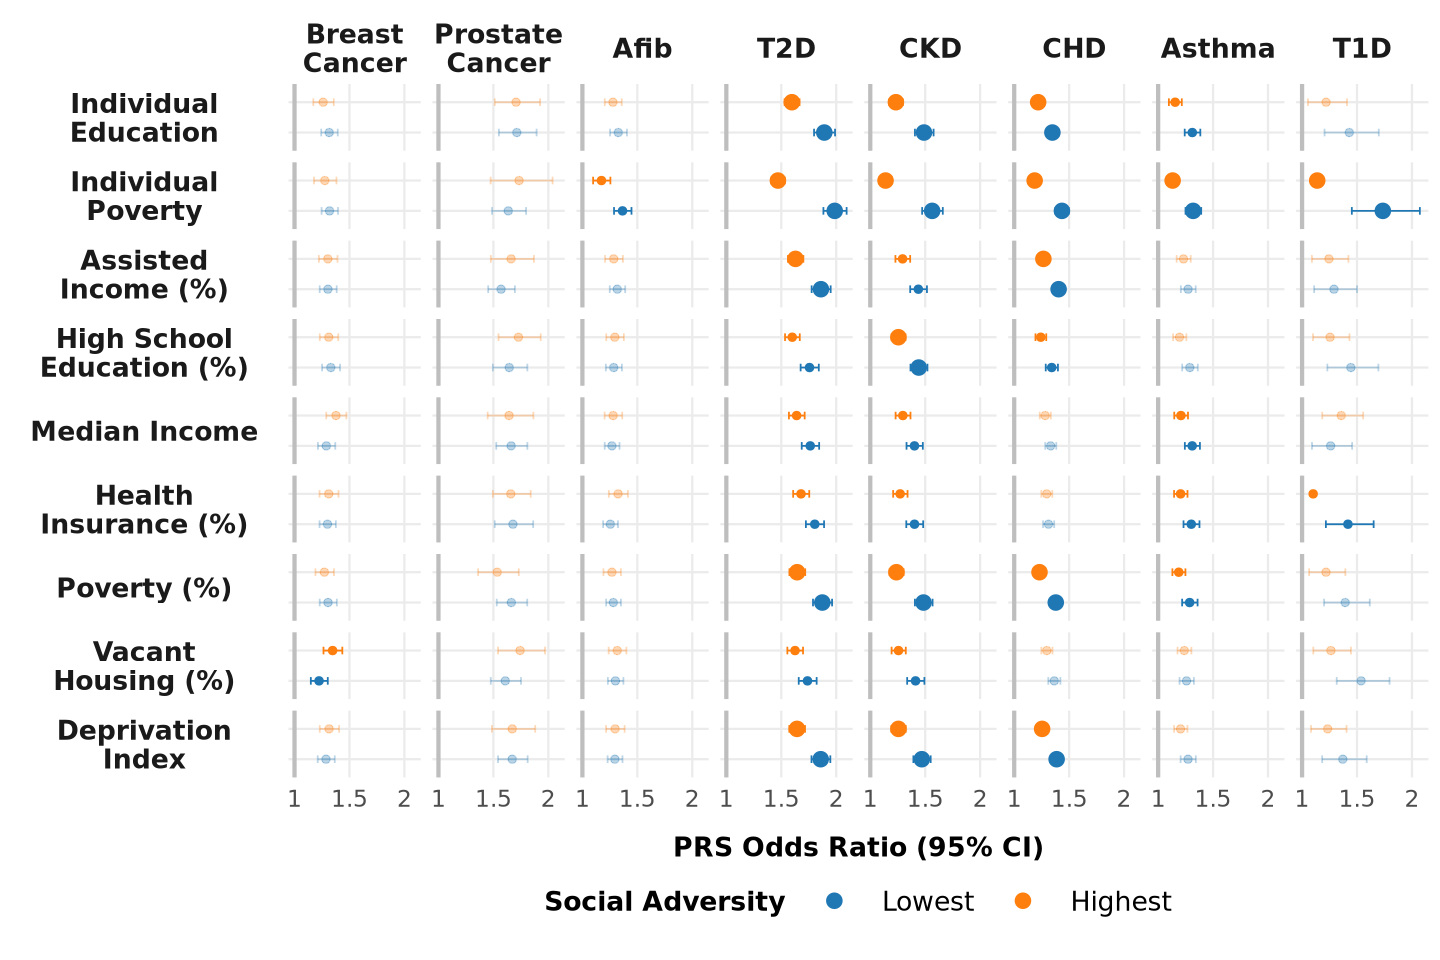

In [14]:
generate_formulas <- function(disease) {
  # Base covariates
  covariates <- c("age", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease %in% c("CKD", "t1d")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease %in% c("BreastC", "ProstateC")) {
    sex_terms <- character(0)
  }

  # Combine covariates
  #base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")

  as.formula(paste(disease, "~", paste(c(score), collapse = " + ")))
}


# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles(formula, disease, sdoh_var, merged_data))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)

#Clean up results
results<-results[results$Quantile_Group %in% c(1,5), ] #Only interested in top and bottom quantiles
results <- results[grep("adjusted_score", results$term), ] #Only interested in PRS term

#Map names for display
results$SDoH_Variable <- social_name_mapping[results$SDoH_Variable] 
results$Disease <- disease_name_mapping[results$Disease]

## -----------------------------
## Recode + order factors
## -----------------------------
results <- results %>%
    mutate(
      Disease       = factor(Disease, levels = disease_order),
      SDoH_Variable = factor(SDoH_Variable, levels = sdoh_order),
      Quantile      = paste0("Q", Quantile_Group)
    ) %>%
    select(
      Disease, SDoH_Variable, Quantile_Group, Quantile,
      term, estimate, std.error, statistic, p.value,
      OR, OR_Lower, OR_Upper,
      AUC, AUC_CI_Lower, AUC_CI_Upper
    )


estimate_q15_out <- prepare_sdoh_prs_forest_data(results)

#Save table
destination_filename <- 'OR_stratified_analyses_no_covariates.csv'
write_excel_csv(estimate_q15_out, destination_filename)
system(paste0("gsutil cp ./", destination_filename, " ", my_bucket, "/data/"), intern=T)
system(paste0("gsutil cp ", my_bucket, "/data/", destination_filename, " ."), intern=T)

p_forest <- plot_sdoh_prs_forest(estimate_q15_out)
print(p_forest)

# Ancestry stratified sensitivity

In [15]:
generate_formulas <- function(disease) {
  # Base covariates
  covariates <- c("age", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease %in% c("CKD", "t1d")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease %in% c("BreastC", "ProstateC")) {
    sex_terms <- character(0)
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")

  as.formula(paste(disease, "~", paste(c(base, score), collapse = " + ")))
}

# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

afr <- merged_data[merged_data$ancestry_pred == "afr",]
eur <- merged_data[merged_data$ancestry_pred == "eur",]

# Step 2: Generate formulas and fit models
results_eur <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles(formula, disease, sdoh_var, eur))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)

#Clean up results
results_eur<-results_eur[results_eur$Quantile_Group %in% c(1,5), ] #Only interested in top and bottom quantiles
results_eur<- results_eur[grep("adjusted_score", results_eur$term), ] #Only interested in PRS term

#Map names for display
results_eur$SDoH_Variable <- social_name_mapping[results_eur$SDoH_Variable] 
results_eur$Disease <- disease_name_mapping[results_eur$Disease]

## -----------------------------
## Recode + order factors
## -----------------------------
results_eur <- results_eur %>%
    mutate(
      Disease       = factor(Disease, levels = disease_order),
      SDoH_Variable = factor(SDoH_Variable, levels = sdoh_order),
      Quantile      = paste0("Q", Quantile_Group),
      Ancestry = "EUR", 
    ) %>%
    select(
      Disease, Ancestry, SDoH_Variable, Quantile_Group, Quantile,
      term, estimate, std.error, statistic, p.value,
      OR, OR_Lower, OR_Upper,
      AUC, AUC_CI_Lower, AUC_CI_Upper
    )

# Step 2: Generate formulas and fit models
results_afr <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles(formula, disease, sdoh_var, afr))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)

#Clean up results
results_afr<-results_afr[results_afr$Quantile_Group %in% c(1,5), ] #Only interested in top and bottom quantiles
results_afr<- results_afr[grep("adjusted_score", results_afr$term), ] #Only interested in PRS term

#Map names for display
results_afr$SDoH_Variable <- social_name_mapping[results_afr$SDoH_Variable] 
results_afr$Disease <- disease_name_mapping[results_afr$Disease]

## -----------------------------
## Recode + order factors
## -----------------------------
results_afr <- results_afr %>%
    mutate(
      Disease       = factor(Disease, levels = disease_order),
      SDoH_Variable = factor(SDoH_Variable, levels = sdoh_order),
      Quantile      = paste0("Q", Quantile_Group),
      Ancestry = "AFR", 
    ) %>%
    select(
      Disease, Ancestry, SDoH_Variable, Quantile_Group, Quantile,
      term, estimate, std.error, statistic, p.value,
      OR, OR_Lower, OR_Upper,
      AUC, AUC_CI_Lower, AUC_CI_Upper
    ) 

results<- rbind(results_eur, results_afr)

Warning message:
“There were 14 warnings in `mutate()`.
The first warning was:
ℹ In argument: `quantile_results = list(fit_by_quantiles(formula, disease,
  sdoh_var, eur))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 13 remaining warnings.”
Warning message:
“There were 2 warnings in `mutate()`.
The first warning was:
ℹ In argument: `quantile_results = list(fit_by_quantiles(formula, disease,
  sdoh_var, afr))`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 1 remaining warning.”


In [16]:
wide <- results %>%
    select(
      Disease, SDoH_Variable, Quantile_Group, estimate,
      OR, std.error, OR_Upper, OR_Lower, Ancestry
    ) %>%
    tidyr::pivot_wider(
      names_from  = Quantile_Group,
      values_from = c(estimate, OR, std.error, OR_Upper, OR_Lower),
      names_sep   = "_"
    )
ann_df <- wide %>%
  mutate(
    var_OR_5 = (OR_5 * std.error_5)^2,
    var_OR_1 = (OR_1 * std.error_1)^2,
    z  = (OR_5 - OR_1) / sqrt(var_OR_5 + var_OR_1),
    z_test_p_value = 2 * pnorm(-abs(z)),
    bonf_sig = z_test_p_value < alpha_bonf,
    fdr_sig      = p.adjust(z_test_p_value, method = "BH") < 0.05,
    sig = z_test_p_value < 0.05
  )

estimate_q15_out <- results %>%
    left_join(
      ann_df %>%
        select(Disease, Ancestry, SDoH_Variable, z, z_test_p_value, bonf_sig, fdr_sig, sig),
      by = c("Disease", "Ancestry", "SDoH_Variable")
    )


#Save table
destination_filename <- 'OR_stratified_analyses_ancestry_stratified.csv'
write_excel_csv(estimate_q15_out, destination_filename)
system(paste0("gsutil cp ./", destination_filename, " ", my_bucket, "/data/"), intern=T)
system(paste0("gsutil cp ", my_bucket, "/data/", destination_filename, " ."), intern=T)

character(0)

character(0)

Warning message:
“Removed 55 rows containing missing values or values outside the scale range
(`geom_errorbarh()`).”
Warning message:
“Removed 72 rows containing missing values or values outside the scale range
(`geom_vline()`).”
Warning message:
“Removed 8 rows containing missing values or values outside the scale range
(`geom_point()`).”


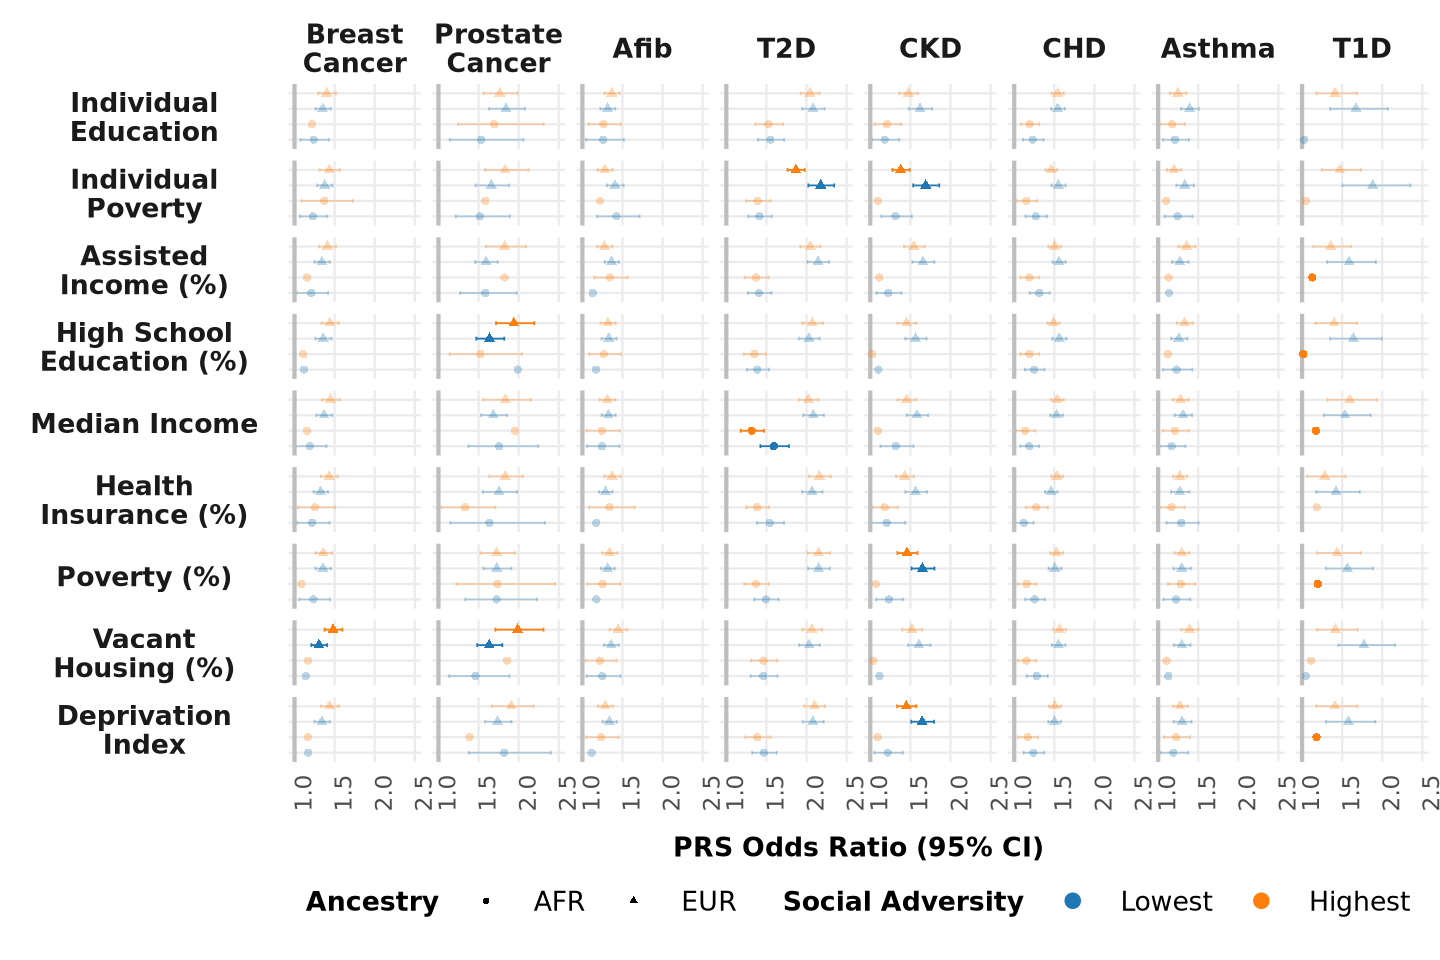

In [17]:
df <- estimate_q15_out
df$y_pos <- interaction(df$Quantile, df$Ancestry, sep = " | ")

x_label <- "PRS Odds Ratio (95% CI)"
ggplot(
    df,
    aes(x = OR, y = y_pos, color = Quantile, shape = Ancestry)
  ) +

    # Error bars (fade if not significant)
    geom_errorbarh(
      aes(
        xmin = OR_Lower,
        xmax = OR_Upper,
        alpha = sig
      ),
      height = 0.25,
      show.legend = FALSE
    ) +

    # Reference lines
    geom_vline(xintercept = 0, color = "grey", linewidth = 1.2) +
    geom_vline(xintercept = 1, color = "grey", linewidth = 1.2) +

    # Points
    geom_point(
      aes(
        alpha = sig,
        size  = bonf_sig,
          group = Ancestry
      )
    ) +

    scale_x_continuous(
      name   = x_label,
      breaks = c(1, 1.5, 2, 2.5),
      limits = c(
        1,
        2.5
      )
    ) +

    scale_color_manual(
      values = c(Q1 = "#1f77b4", Q5 = "#ff7f0e"),
      labels = c(
        Q1 = "Lowest",
        Q5 = "Highest"
      )
    ) +

    scale_size_manual(
      values = c(`FALSE` = 2, `TRUE` = 5),
      guide  = "none"
    ) +

    scale_alpha_manual(
      values = c(`FALSE` = 0.3, `TRUE` = 1),
      guide  = "none"
    ) +

    labs(
      y     = "Quantile",
      color = "Social Adversity"
    ) +
    facet_grid(
      rows   = vars(SDoH_Variable),
      cols   = vars(Disease),
      scales = "free_y",
      switch = "y"
    ) +

    theme_minimal(base_size = 14) +
    theme(
      axis.text.x        = element_text(size = 14, margin = margin(t = 4), angle = 90),
      panel.grid.minor   = element_blank(),
      axis.title.y       = element_blank(),
      axis.title.x       = element_text(size = 16, face = "bold", margin = margin(t = 15)),
      axis.text.y        = element_blank(),
      strip.text.y.left  = element_text(size = 16, angle = 0, face = "bold", vjust = 0.5),
      strip.placement    = "outside",
      strip.text.x       = element_text(size = 16, face = "bold"),
      legend.position    = "bottom",
      legend.box.spacing = unit(-5, "pt"),
      legend.text        = element_text(size = 16),
      legend.title       = element_text(size = 16, face = "bold"),
      legend.key.size    = unit(3, "lines")
    ) +

    guides(
      color = guide_legend(override.aes = list(size = 4))
    )

## Down sample to AFR case/control sizes

In [29]:
afr_counts <- data.frame(
  disease = diseases,
  cases = sapply(diseases, function(disease) sum(afr[[disease]] == 1, na.rm = TRUE)),
  controls = sapply(diseases, function(disease) sum(afr[[disease]] == 0, na.rm = TRUE))
)

afr_counts

data.frame(
  disease = diseases,
  cases = sapply(diseases, function(disease) sum(eur[[disease]] == 1, na.rm = TRUE)),
  controls = sapply(diseases, function(disease) sum(eur[[disease]] == 0, na.rm = TRUE))
)
             

,disease,cases,controls
,<chr>,<int>,<int>
Asthma,Asthma,2613,3849
Afib,Afib,887,4050
BreastC,BreastC,702,12396
CKD,CKD,2386,4637
CHD,CHD,2506,15742
ProstateC,ProstateC,451,601
t2d,t2d,4715,4282
t1d,t1d,219,4282


,disease,cases,controls
,<chr>,<int>,<int>
Asthma,Asthma,7983,11137
Afib,Afib,6883,11457
BreastC,BreastC,4141,39343
CKD,CKD,6097,20927
CHD,CHD,11047,58100
ProstateC,ProstateC,2962,5118
t2d,t2d,10530,27176
t1d,t1d,751,27176


In [30]:
                 
set.seed(67)

downsampled_merged <- lapply(diseases, function(disease) {
  n_cases <- afr_counts$cases[afr_counts$disease == disease]
  n_controls <- afr_counts$controls[afr_counts$disease == disease]

  cases_df <- merged_data[merged_data[[disease]] == 1 & !is.na(merged_data[[disease]]), ]
  controls_df <- merged_data[merged_data[[disease]] == 0 & !is.na(merged_data[[disease]]), ]

  data.frame(
    rbind(
      cases_df[sample(nrow(cases_df), min(n_cases, nrow(cases_df))), ],
      controls_df[sample(nrow(controls_df), min(n_controls, nrow(controls_df))), ]
    ),
    matched_disease = disease
  )
})

downsampled_merged <- do.call(rbind, downsampled_merged)

fit_by_quantiles_downsampled <- function(formula, disease, sdoh_var, data, n_quantiles = 5) {

  data <- data[data$matched_disease == disease,]
  
  # Create quantile groups
  data <- data %>%
    filter(!is.na(.data[[sdoh_var]])) %>%
    mutate(quantile_group = ntile(.data[[sdoh_var]], n_quantiles))
    
  # Disease specific filters
  if (disease %in% c("CKD", "t1d")) data <- data %>% filter(SexGenderSGM == 0)
  if (disease == "BreastC")         data <- data %>% filter(SexGenderCis_female == 1)
  if (disease == "ProstateC")       data <- data %>% filter(SexGenderCis_male == 1)

  # Fit models for each quantile group
  results <- data %>%
    group_by(quantile_group) %>%
    group_map(~ {

      # Fit the model
      model <- glm(formula, data = .x, family = binomial(link = "logit"))
      
      # Calculate predictions and AUC
      preds <- predict(model, type = "response")
      actuals <- model$y

      if (length(unique(actuals)) > 1) {
        roc_obj <- roc(actuals, preds, quiet = TRUE)
        auc <- as.numeric(roc_obj$auc)
        auc_ci <- ci.auc(roc_obj)
      } else {
        auc <- NA
        auc_ci <- c(NA, NA, NA)
      }
      
      # Extract model coefficients
      tidy(model) %>%
        mutate(
          Disease = disease,
          Quantile_Group = .y$quantile_group,  # Properly carried from the group key
          SDoH_Variable = sdoh_var,
          AUC = auc,
          AUC_CI_Lower = auc_ci[1],
          AUC_CI_Upper = auc_ci[3],
          OR = exp(estimate),
         OR_Lower = exp(estimate - 1.96 * std.error),
         OR_Upper = exp(estimate + 1.96 * std.error)
        )
    }) %>%
    bind_rows()

  return(results)
}

# Step 2: Generate formulas and fit models
results_downsampled <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles_downsampled(formula, disease, sdoh_var, downsampled_merged))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)

#Clean up results
results_downsampled<-results_downsampled[results_downsampled$Quantile_Group %in% c(1,5), ] #Only interested in top and bottom quantiles
results_downsampled<- results_downsampled[grep("adjusted_score", results_downsampled$term), ] #Only interested in PRS term

#Map names for display
results_downsampled$SDoH_Variable <- social_name_mapping[results_downsampled$SDoH_Variable] 
results_downsampled$Disease <- disease_name_mapping[results_downsampled$Disease]

## -----------------------------
## Recode + order factors
## -----------------------------
results_downsampled <- results_downsampled %>%
    mutate(
      Disease       = factor(Disease, levels = disease_order),
      SDoH_Variable = factor(SDoH_Variable, levels = sdoh_order),
      Quantile      = paste0("Q", Quantile_Group),
      Ancestry = "EUR", 
    ) %>%
    select(
      Disease, SDoH_Variable, Quantile_Group, Quantile,
      term, estimate, std.error, statistic, p.value,
      OR, OR_Lower, OR_Upper,
      AUC, AUC_CI_Lower, AUC_CI_Upper
    )

estimate_q15_out <- prepare_sdoh_prs_forest_data(results_downsampled)

#Save table
destination_filename <- 'OR_stratified_analyses_downsampled.csv'
write_excel_csv(estimate_q15_out, destination_filename)
system(paste0("gsutil cp ./", destination_filename, " ", my_bucket, "/data/"), intern=T)
system(paste0("gsutil cp ", my_bucket, "/data/", destination_filename, " ."), intern=T)

Warning message:
“There were 4 warnings in `mutate()`.
The first warning was:
ℹ In argument: `quantile_results = list(...)`.
ℹ In row 1.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 3 remaining warnings.”


character(0)

character(0)

Warning message:
“Removed 25 rows containing missing values or values outside the scale range
(`geom_errorbarh()`).”
Warning message:
“Removed 72 rows containing missing values or values outside the scale range
(`geom_vline()`).”
Warning message:
“Removed 1 row containing missing values or values outside the scale range
(`geom_point()`).”


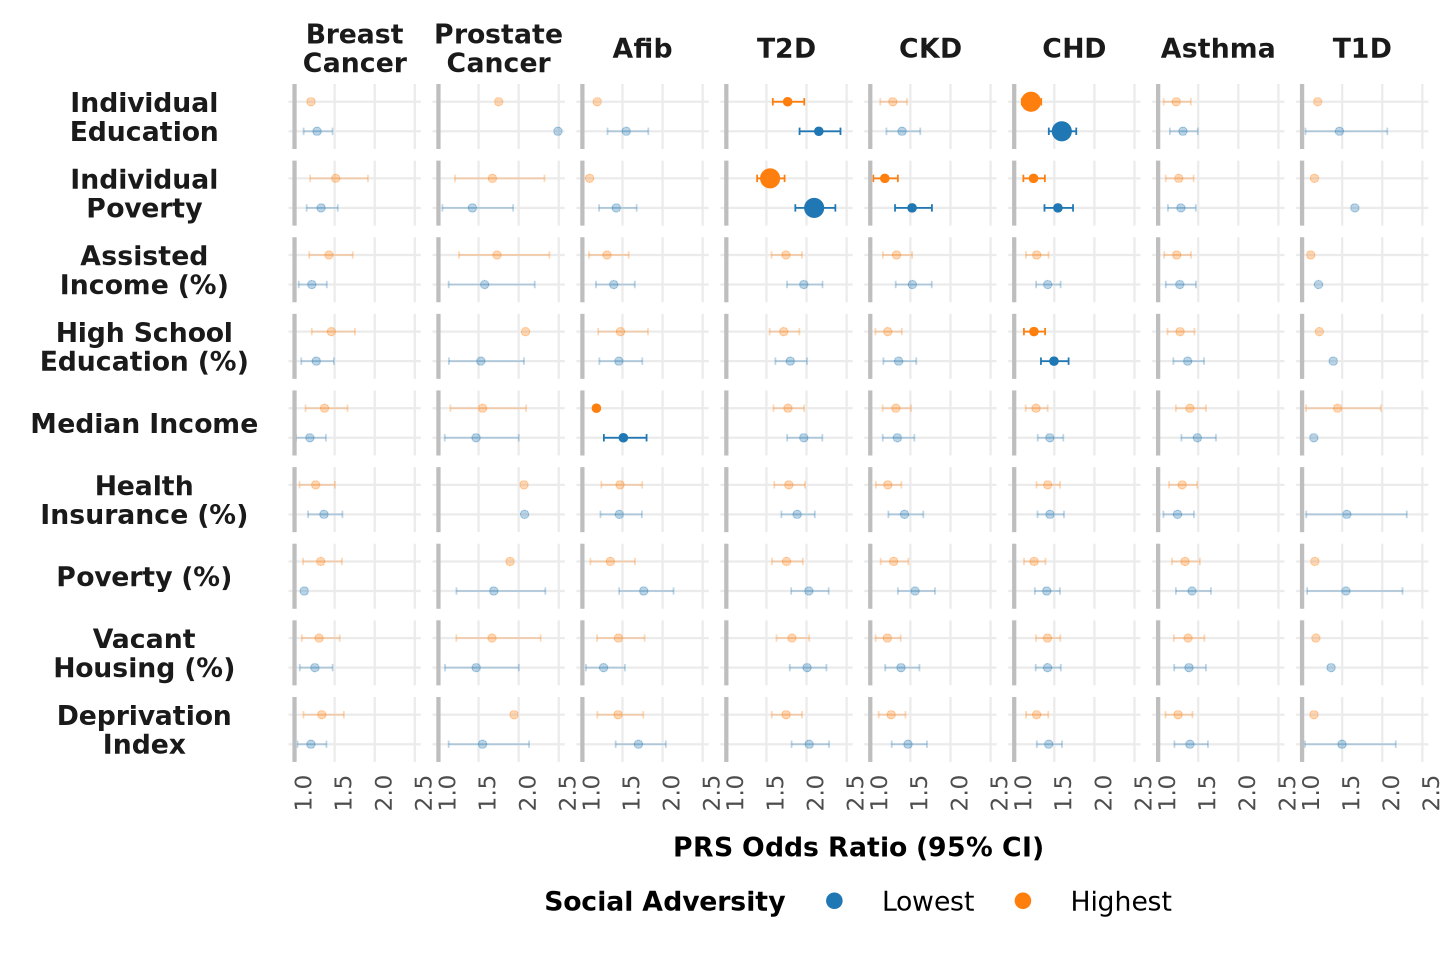

In [31]:
df <- estimate_q15_out

x_label <- "PRS Odds Ratio (95% CI)"
ggplot(
    df,
    aes(x = OR, y = Quantile, color = Quantile)
  ) +

    # Error bars (fade if not significant)
    geom_errorbarh(
      aes(
        xmin = OR_Lower,
        xmax = OR_Upper,
        alpha = sig
      ),
      height = 0.25,
      show.legend = FALSE
    ) +

    # Reference lines
    geom_vline(xintercept = 0, color = "grey", linewidth = 1.2) +
    geom_vline(xintercept = 1, color = "grey", linewidth = 1.2) +

    # Points
    geom_point(
      aes(
        alpha = sig,
        size  = bonf_sig
      )
    ) +

    scale_x_continuous(
      name   = x_label,
      breaks = c(1, 1.5, 2, 2.5),
      limits = c(
        1,
        2.5
      )
    ) +

    scale_color_manual(
      values = c(Q1 = "#1f77b4", Q5 = "#ff7f0e"),
      labels = c(
        Q1 = "Lowest",
        Q5 = "Highest"
      )
    ) +

    scale_size_manual(
      values = c(`FALSE` = 2, `TRUE` = 5),
      guide  = "none"
    ) +

    scale_alpha_manual(
      values = c(`FALSE` = 0.3, `TRUE` = 1),
      guide  = "none"
    ) +

    labs(
      y     = "Quantile",
      color = "Social Adversity"
    ) +
    facet_grid(
      rows   = vars(SDoH_Variable),
      cols   = vars(Disease),
      scales = "free_y",
      switch = "y"
    ) +

    theme_minimal(base_size = 14) +
    theme(
      axis.text.x        = element_text(size = 14, margin = margin(t = 4), angle = 90),
      panel.grid.minor   = element_blank(),
      axis.title.y       = element_blank(),
      axis.title.x       = element_text(size = 16, face = "bold", margin = margin(t = 15)),
      axis.text.y        = element_blank(),
      strip.text.y.left  = element_text(size = 16, angle = 0, face = "bold", vjust = 0.5),
      strip.placement    = "outside",
      strip.text.x       = element_text(size = 16, face = "bold"),
      legend.position    = "bottom",
      legend.box.spacing = unit(-5, "pt"),
      legend.text        = element_text(size = 16),
      legend.title       = element_text(size = 16, face = "bold"),
      legend.key.size    = unit(3, "lines")
    ) +

    guides(
      color = guide_legend(override.aes = list(size = 4))
    )

# Sensitivity analysis using non-PC adjusted PRS

In [ ]:
library(tidyverse)

# Define conditions and readable disease names
conditions <- c(
  "asthma",
  "atrial_fibrilation",
  "breast_cancer",
  "ckd",
  "coronary_heart_disease",
  "prostate_cancer",
  "t1d",
  "t2d"
)

disease_labels <- c(
  "Asthma",
  "Afib",
  "BreastC",
  "CKD",
  "CHD",
  "ProstateC",
  "t2d",
  "t1d"
)


all_prs <- NULL


# Loop through all conditions
for (i in seq_along(conditions)) {
  condition <- conditions[i]
  disease <- disease_labels[i]
  
  # Define filename
  name_of_file_in_bucket <- paste0("combined_", condition, ".txt")
  
  # Download from GCS
  system(
    paste0(
      "gsutil cp ", my_bucket, "/data/",
      name_of_file_in_bucket,
      " ."
    ),
    intern = TRUE
  )
  
  # Read CSV
  prs <- read_csv(name_of_file_in_bucket, show_col_types = FALSE) |> select(1,4)
  
  # Add disease label and rename the score column
  prs <- prs %>%
  rename(!!paste0(disease, "_score") := 2) %>%
  rename("person_id" := 1)
  
  # Merge by IID
  if (is.null(all_prs)) {
    all_prs <- prs
  } else {
    all_prs <- merge(all_prs, prs, by = "person_id")
  }
}


#MERGE
demo_sdoh<-merge(demo, sdoh_data, on="person_id", how="inner")

#MERGE
all_data_0<-merge(demo_sdoh, all_prs, on="person_id", how="inner")

#MERGE
merged_data<-merge(all_data_0, case_control, on="person_id", how="left")

merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

merged_data$per_poverty_threshold <- 1 - merged_data$per_poverty_threshold

merged_data <- merged_data %>%
  mutate(across(all_of(sdoh_var), ~ (.-min(., na.rm = TRUE)) / 
                               (max(., na.rm = TRUE) - min(., na.rm = TRUE))))

merged_data <- merged_data %>%
  mutate(
    across(
      ends_with("_score"),
      ~ (. - mean(., na.rm = TRUE)) / sd(., na.rm = TRUE)
    )
  )

In [ ]:
generate_formulas <- function(disease) {
  # Base covariates
  covariates <- c("age", "record_depth", "visit_frequency", paste0("PC_", 1:16))
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease %in% c("CKD", "t1d")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease %in% c("BreastC", "ProstateC")) {
    sex_terms <- character(0)
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_score")

  as.formula(paste(disease, "~", paste(c(base, score), collapse = " + ")))
}

# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles(formula, disease, sdoh_var, merged_data))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)

#Clean up results
results<-results[results$Quantile_Group %in% c(1,5), ] #Only interested in top and bottom quantiles
results <- results[grep("_score", results$term), ] #Only interested in PRS term

#Map names for display
results$SDoH_Variable <- social_name_mapping[results$SDoH_Variable] 
results$Disease <- disease_name_mapping[results$Disease]

## -----------------------------
## Recode + order factors
## -----------------------------
results <- results %>%
    mutate(
      Disease       = factor(Disease, levels = disease_order),
      SDoH_Variable = factor(SDoH_Variable, levels = sdoh_order),
      Quantile      = paste0("Q", Quantile_Group)
    ) %>%
    select(
      Disease, SDoH_Variable, Quantile_Group, Quantile,
      term, estimate, std.error, statistic, p.value,
      OR, OR_Lower, OR_Upper,
      AUC, AUC_CI_Lower, AUC_CI_Upper
    )



estimate_q15_out <- prepare_sdoh_prs_forest_data(results)

#Save table
destination_filename <- 'OR_stratified_analyses_non_adjusted_PRS.csv'
write_excel_csv(estimate_q15_out, destination_filename)
system(paste0("gsutil cp ./", destination_filename, " ", my_bucket, "/data/"), intern=T)
system(paste0("gsutil cp ", my_bucket, "/data/", destination_filename, " ."), intern=T)

In [ ]:
plot_sdoh_prs_forest2 <- function(
  df,
  width  = 12,
  height = 8,
  x_label = "PRS Odds Ratio (95% CI)"
) {

  p <- ggplot(
    df,
    aes(x = OR, y = Quantile, color = Quantile)
  ) +

    # Error bars (fade if not significant)
    geom_errorbarh(
      aes(
        xmin = OR_Lower,
        xmax = OR_Upper,
        alpha = sig
      ),
      height = 0.25,
      show.legend = FALSE
    ) +

    # Reference lines
    geom_vline(xintercept = -.5, color = "grey", linewidth = 1.2) +
    geom_vline(xintercept = 0, color = "grey", linewidth = 1.2, linetype = "dashed") +
    geom_vline(xintercept = 1.5, color = "grey", linewidth = 1.2) +

    # Points
    geom_point(
      aes(
        alpha = sig,
        size  = bonf_sig
      )
    ) +

    scale_x_continuous(
      name   = x_label,
      breaks = c(-0.5, 0, 0.5, 1, 1.5),
      limits = c(
        -0.5,
        max(1.5, max(df$OR_Upper, na.rm = TRUE))
      )
    ) +

    scale_color_manual(
      values = c(Q1 = "#1f77b4", Q5 = "#ff7f0e"),
      labels = c(
        Q1 = "Lowest",
        Q5 = "Highest"
      )
    ) +

    scale_size_manual(
      values = c(`FALSE` = 2, `TRUE` = 4),
      guide  = "none"
    ) +

    scale_alpha_manual(
      values = c(`FALSE` = 0.3, `TRUE` = 1),
      guide  = "none"
    ) +

    labs(
      y     = "Quantile",
      color = "Social Adversity"
    ) +

    facet_grid(
      rows   = vars(SDoH_Variable),
      cols   = vars(Disease),
      scales = "free_y",
      switch = "y"
    ) +

    theme_minimal(base_size = 14) +
    theme(
      axis.text.x        = element_text(size = 14, margin = margin(t = 4), angle = 90),
      panel.grid.minor   = element_blank(),
      axis.title.y       = element_blank(),
      axis.title.x       = element_text(size = 16, face = "bold", margin = margin(t = 15)),
      axis.text.y        = element_blank(),
      strip.text.y.left  = element_text(size = 16, angle = 0, face = "bold", vjust = 0.5),
      strip.placement    = "outside",
      strip.text.x       = element_text(size = 16, face = "bold"),
      legend.position    = "bottom",
      legend.box.spacing = unit(-5, "pt"),
      legend.text        = element_text(size = 16),
      legend.title       = element_text(size = 16, face = "bold"),
      legend.key.size    = unit(3, "lines")
    ) +

    guides(
      color = guide_legend(override.aes = list(size = 4))
    )

  options(
    repr.plot.width  = width,
    repr.plot.height = height
  )

  p
}

p_forest <- plot_sdoh_prs_forest2(estimate_q15_out)
print(p_forest)